In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

In [ ]:
image_folder = Path(
    r""C:\academics\codes\DSIP\images""
)

image1 = cv2.imread(str(image_folder / "1.jpeg"))
image2 = cv2.imread(str(image_folder / "2.jpeg"))
image3 = cv2.imread(str(image_folder / "3.jpeg"))

if any(img is None for img in [image1, image2, image3]):
    raise FileNotFoundError("Check the image filenames and locations.")

print("Image 1:", image1.shape)
print("Image 2:", image2.shape)
print("Image 3:", image3.shape)

Image 1: (370, 408, 3)
Image 2: (387, 414, 3)
Image 3: (393, 620, 3)


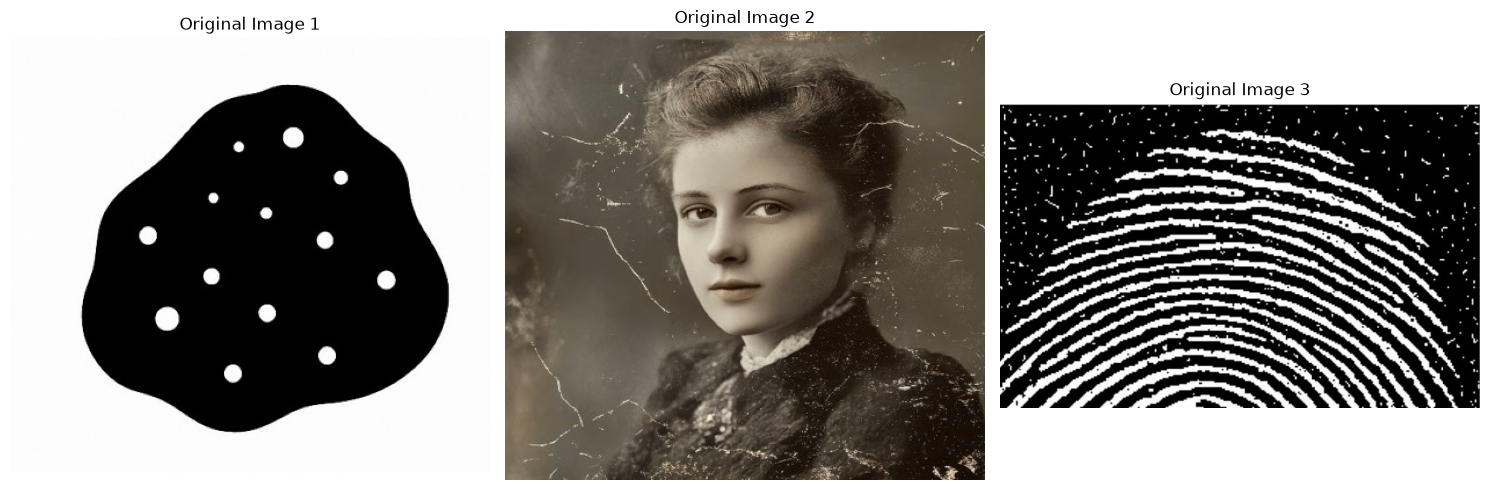

In [15]:
plt.figure(figsize=(15, 5))

original_images = [image1, image2, image3]

for i, image in enumerate(original_images):

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(f"Original Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

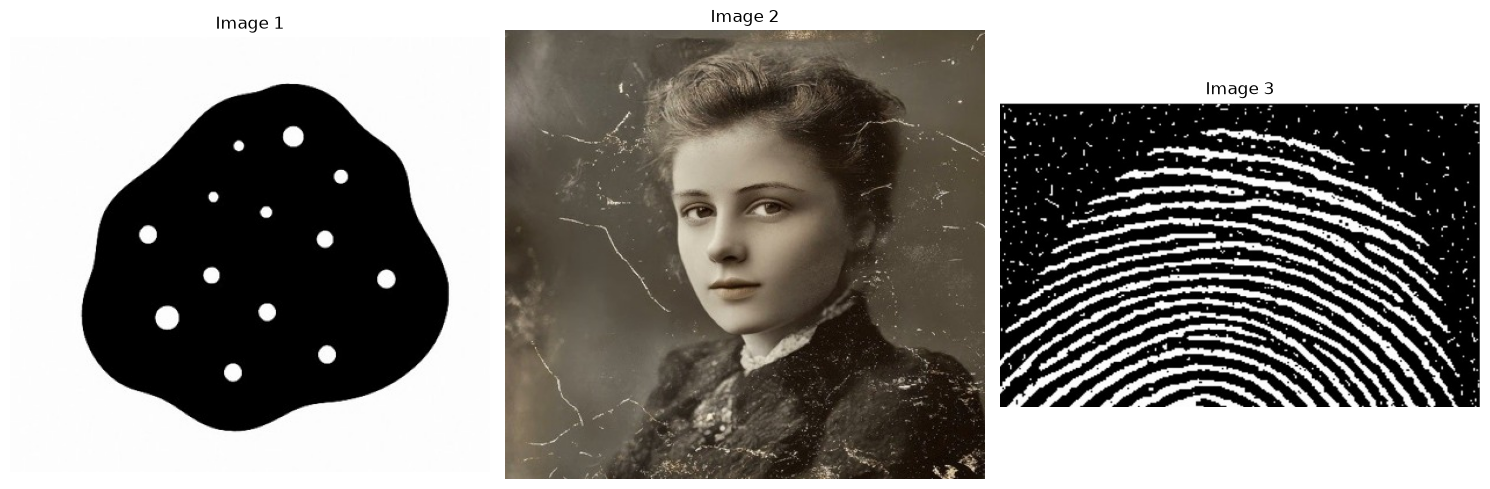

In [5]:
plt.figure(figsize=(15, 5))

for i, (name, image) in enumerate(images.items()):

    plt.subplot(1, 3, i + 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [6]:
gray_images = {}

for name, image in images.items():

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray_images[name] = gray

print("Grayscale conversion completed!")

Grayscale conversion completed!


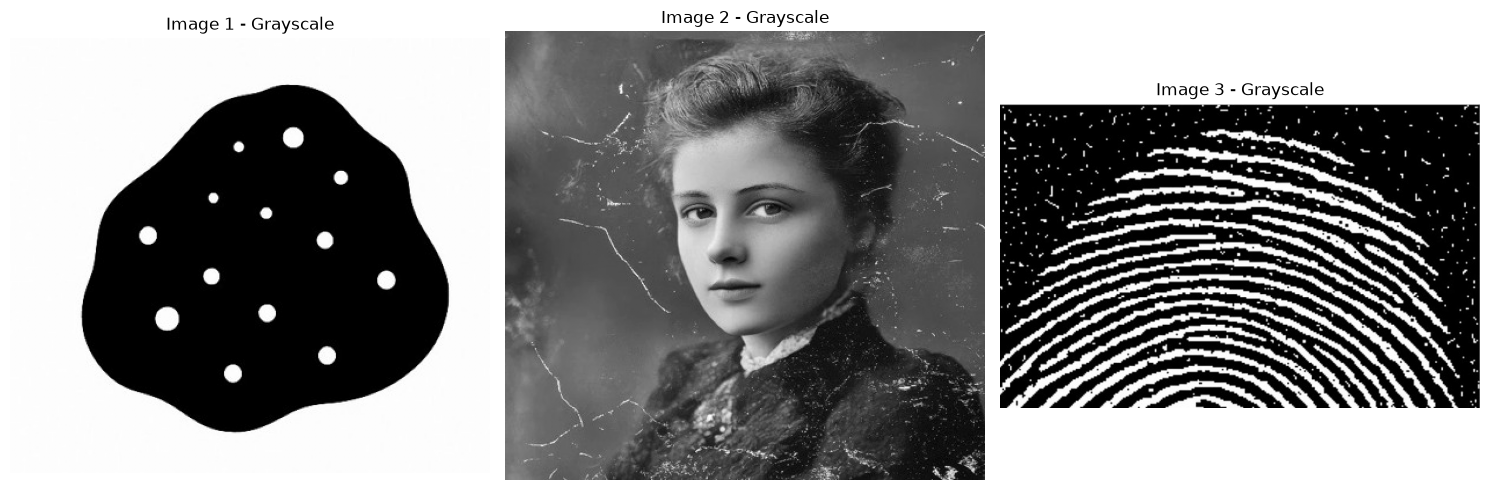

In [ ]:
plt.figure(figsize=(15, 5))

for i, (name, image) in enumerate(gray_images.items()):

    plt.subplot(1, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(name + " - Grayscale")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
binary_images = {}

_, binary_images["Image 1"] = cv2.threshold(
    cv2.cvtColor(image1, cv2.COLOR_BGR2GRAY),
    0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

_, binary_images["Image 3"] = cv2.threshold(
    cv2.cvtColor(image3, cv2.COLOR_BGR2GRAY),
    0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Binary conversion completed!")

Binary conversion completed!


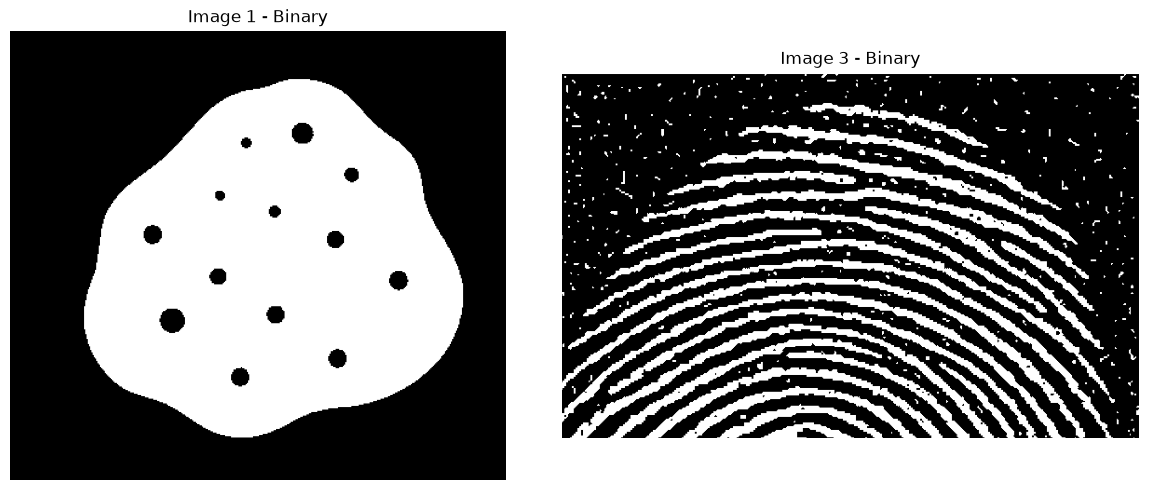

In [9]:
plt.figure(figsize=(12, 5))

for i, name in enumerate(["Image 1", "Image 3"]):

    plt.subplot(1, 2, i + 1)
    plt.imshow(binary_images[name], cmap="gray")
    plt.title(name + " - Binary")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
kernel_3 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

kernel_5 = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (5, 5)
)

print("Structuring elements created successfully!")

Structuring elements created successfully!


In [17]:
opened_images = {}

for name, image in binary_images.items():

    opened_images[name] = cv2.morphologyEx(
        image,
        cv2.MORPH_OPEN,
        kernel_3,
        iterations=1
    )

print("Opening completed!")

Opening completed!


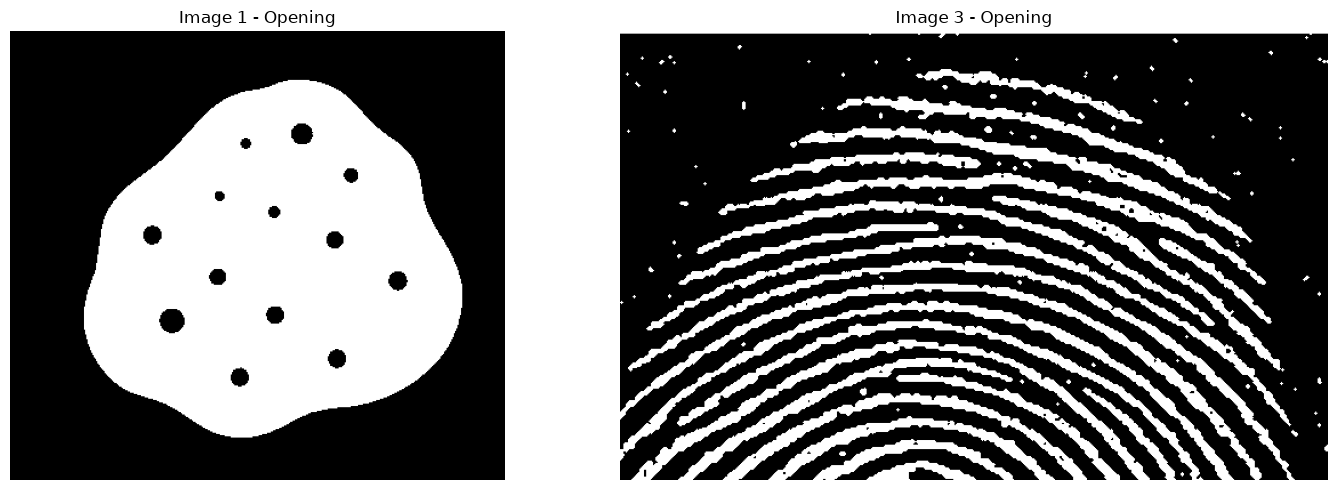

In [18]:
plt.figure(figsize=(15, 5))

for i, name in enumerate(opened_images):

    plt.subplot(1, 2, i + 1)
    plt.imshow(opened_images[name], cmap="gray")
    plt.title(name + " - Opening")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [19]:
processed_binary = {}

for name, image in opened_images.items():

    kernel = kernel_5 if name == "Image 1" else kernel_3

    closed = cv2.morphologyEx(
        image,
        cv2.MORPH_CLOSE,
        kernel,
        iterations=1
    )

    processed_binary[name] = closed

print("Morphological closing completed!")

Morphological closing completed!


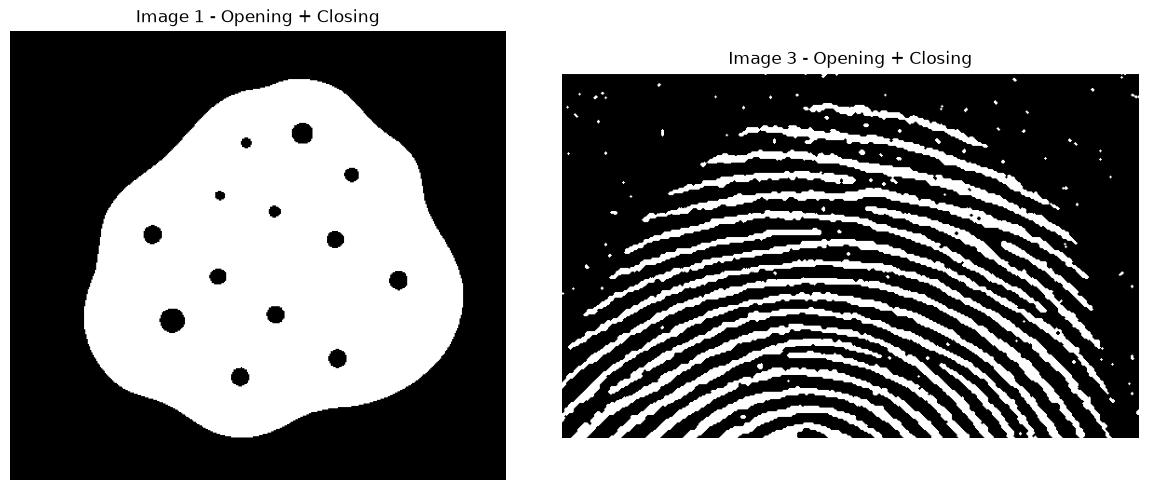

In [20]:
plt.figure(figsize=(12, 5))

for i, name in enumerate(processed_binary):

    plt.subplot(1, 2, i + 1)
    plt.imshow(processed_binary[name], cmap="gray")
    plt.title(name + " - Opening + Closing")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
photo = gray_images["Image 2"]

tophat = cv2.morphologyEx(
    photo,
    cv2.MORPH_TOPHAT,
    kernel_3
)

blackhat = cv2.morphologyEx(
    photo,
    cv2.MORPH_BLACKHAT,
    kernel_5
)

cleaned_photo = cv2.subtract(photo, tophat)

cleaned_photo = cv2.add(
    cleaned_photo,
    blackhat
)

print("Grayscale morphological processing completed!")

Grayscale morphological processing completed!


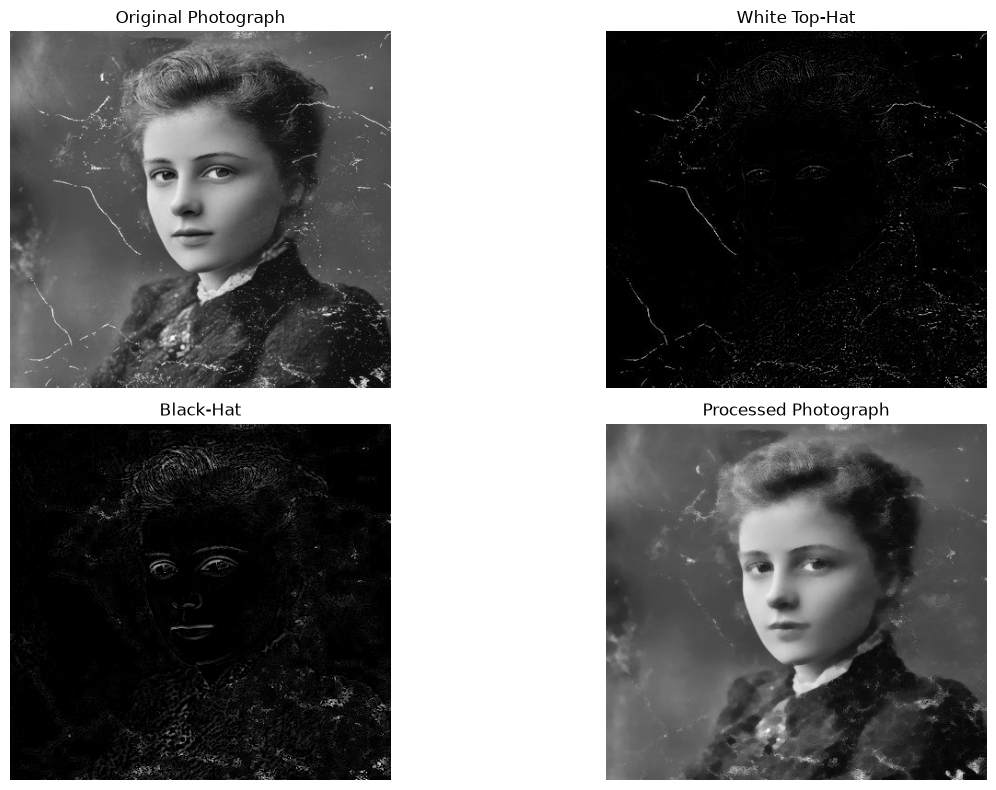

In [22]:
plt.figure(figsize=(14, 8))

results = [
    photo,
    tophat,
    blackhat,
    cleaned_photo
]

titles = [
    "Original Photograph",
    "White Top-Hat",
    "Black-Hat",
    "Processed Photograph"
]

for i in range(4):

    plt.subplot(2, 2, i + 1)
    plt.imshow(results[i], cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()

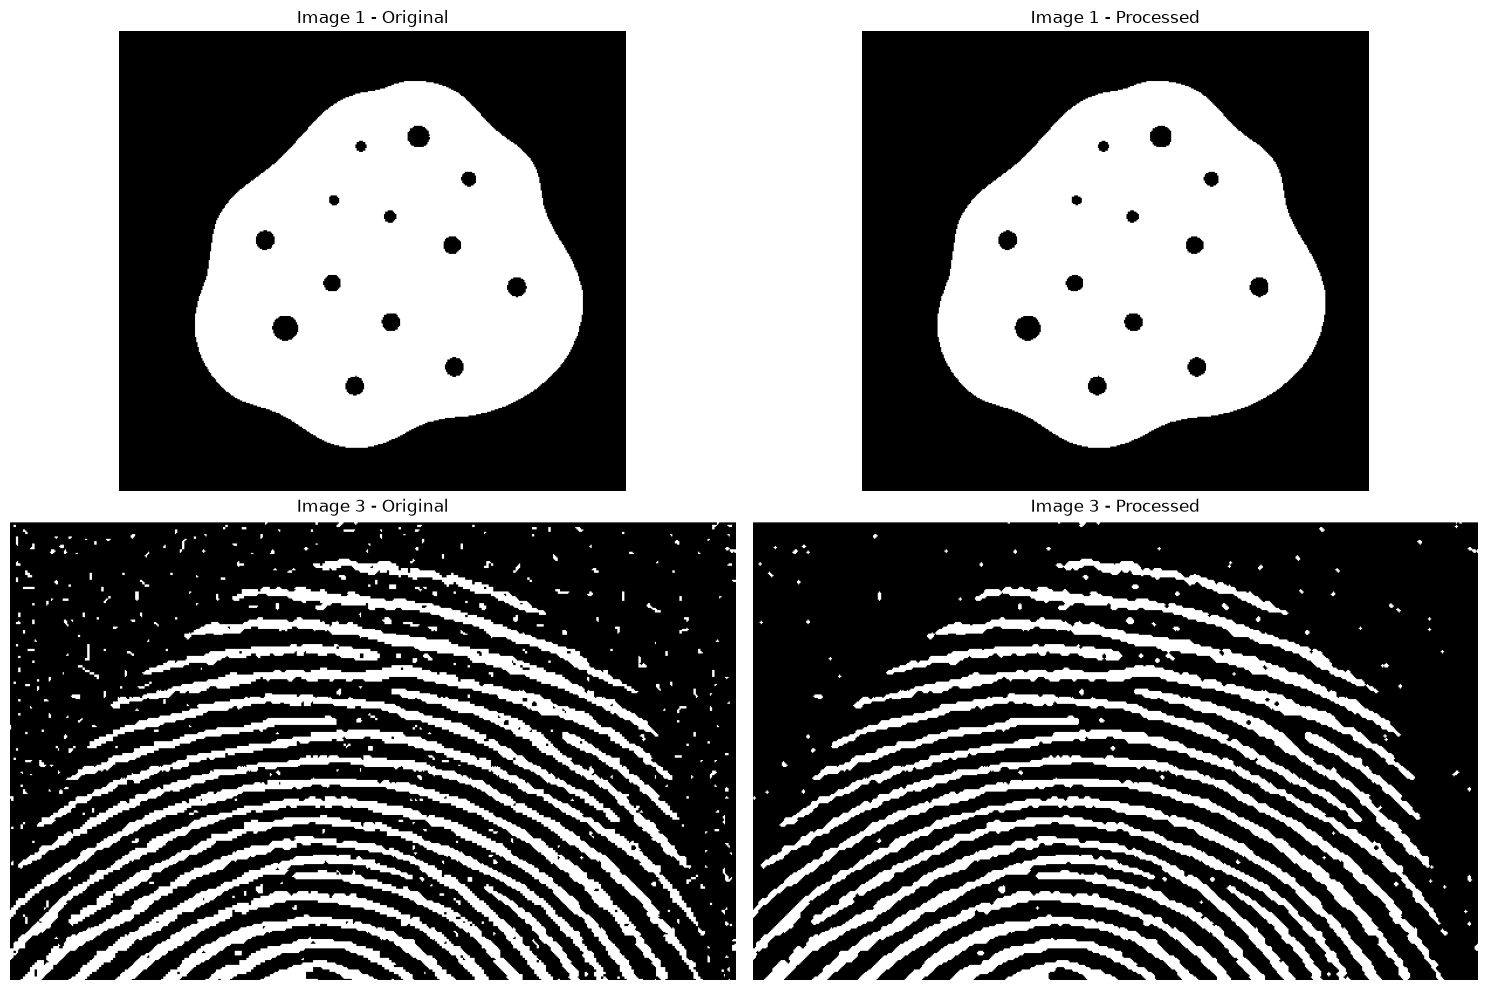

In [23]:
plt.figure(figsize=(15, 10))

for i, name in enumerate(["Image 1", "Image 3"]):

    plt.subplot(2, 2, 2 * i + 1)
    plt.imshow(binary_images[name], cmap="gray")
    plt.title(name + " - Original")
    plt.axis("off")

    plt.subplot(2, 2, 2 * i + 2)
    plt.imshow(processed_binary[name], cmap="gray")
    plt.title(name + " - Processed")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
output_folder = image_folder / "Processed_Images"
output_folder.mkdir(exist_ok=True)

for name, image in processed_binary.items():

    filename = name.replace(" ", "_") + "_Processed.png"

    cv2.imwrite(
        str(output_folder / filename),
        image
    )

cv2.imwrite(
    str(output_folder / "Image_2_Processed.png"),
    cleaned_photo
)

print("All processed images saved successfully!")
print("Output folder:", output_folder)

All processed images saved successfully!
Output folder: C:\Users\devah\Documents\ICT MU\Sem 5\DSIP\Lab\Images\OPE 6\Processed_Images
